## Baseline and core modelling

Comparing models for predicting half-hourly transmission system demand in Great Britain. Models are trained on 2023–2024 data and evaluated on 2025 observations. 3 simple baselines are included to assess whether machine learning improves on predictions based on previous demand. The experiment evaluates prediction under observed conditions but it does not simulate an operational day-ahead forecast.

Performance is examined across seasons and times of day, alongside experiments assessing the contribution of different feature groups.

### 2. Setup and data loading

In [1]:
import sqlite3, time, warnings   
from pathlib import Path 
import numpy as np  
import pandas as pd    
import matplotlib.pyplot as plt    

from sklearn.linear_model import LinearRegression, Ridge   
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor   
from sklearn.preprocessing import StandardScaler   
from sklearn.pipeline import Pipeline    
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit    
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor  
from lightgbm import LGBMRegressor        

warnings.filterwarnings("ignore", category=FutureWarning)

CWD=Path.cwd()
PROJECT_ROOT=CWD.parent if CWD.name=="notebooks" else CWD  
DB_PATH=PROJECT_ROOT / "database" / "energy.db"
FIG_DIR=PROJECT_ROOT / "figures"; FIG_DIR.mkdir(exist_ok=True)

#Plot config
plt.rcParams.update({
    "figure.dpi":110, "savefig.dpi":200, "savefig.bbox": "tight",
    "font.size":10, "axes.titlesize":12, "axes.titleweight":"bold",
    "axes.spines.top":False, "axes.spines.right":False,
    "axes.grid":True, "grid.alpha":0.25, "figure.facecolor": "white",
})

C={"primary": "#1B4965", "accent": "#D95F02", "muted": "#9E9E9E", "good": "#2166AC"}

conn=sqlite3.connect(DB_PATH)

df=pd.read_sql_query("SELECT * FROM model_features_tbl ORDER BY settlement_date, settlement_period;", conn)
df["date"]=pd.to_datetime(df["settlement_date"])

print(f"{len(df):,} rows x {df.shape[1]} columns")
print(f"Period: {df['settlement_date'].min()} to {df['settlement_date'].max()}")




51,258 rows x 50 columns
Period: 2023-01-29 to 2025-12-31


### 3. Splitting

TRaining on 2023-2024 and testing on all of 2025 gives a full year of test data covering every season. A random split would put July
2025 in training and August 2025 in test, letting the model learn 2025's conditions (for example the embedded_solar) before being asked to
predict them.
Feature availability and the construction of lags and rolling averages must also be checked separately.

In [2]:
SPLIT_DATE="2025-01-01"

train=df[df["settlement_date"]<SPLIT_DATE].copy()
test=df[df["settlement_date"]>=SPLIT_DATE].copy()

print(f"Train: {len(train):>7,} rows  {train['settlement_date'].min()} to {train['settlement_date'].max()}")
print(f"Test:  {len(test):>7,} rows {test['settlement_date'].min()} to {test['settlement_date'].max()}")
print(f"Test proportion: {len(test)/len(df):.1%}")

#Safety check
assert train["settlement_date"].max() < test["settlement_date"].min(), "Split overlaps"

print("\nMean demand by split:")
print(f" train {train['tsd_mw'].mean():>9,.0f} MW")
print(f" test  {test['tsd_mw'].mean():>9,.0f} MW "
      f"({test['tsd_mw'].mean()/train['tsd_mw'].mean()-1:+.1%})")



Train:  33,740 rows  2023-01-29 to 2024-12-31
Test:   17,518 rows 2025-01-01 to 2025-12-31
Test proportion: 34.2%

Mean demand by split:
 train    27,882 MW
 test     28,564 MW (+2.4%)


In [3]:
############ Feature selection #############

TARGET="tsd_mw"

#Excluding leaky features
LEAKY=["tsd_mw", "nd_mw", "underlying_demand_mw"]

#Excluding identifiers
NON_FEATURES=["settlement_date", "date", "time_label", "day_name",
              "period_of_day", "season"]

FEATURES=[c for c in df.columns if c not in LEAKY + NON_FEATURES]

#Removing rows with NULL lags (clock_change rows)
def prepare(frame):
    sub=frame.dropna(subset=FEATURES + [TARGET])
    return sub[FEATURES], sub[TARGET], sub

X_train, y_train, train_c=prepare(train)
X_test, y_test, test_c=prepare(test)

print(f"Features used: {len(FEATURES)}")
print(f"Train rows after dropping NULLs: {len(X_train):,} (lost {len(train)-len(X_train)})")
print(f"Test rows after dropping NULLs:  {len(X_test):,} (lost {len(test)-len(X_test)})")
print("\nFeature list:")
print(", ".join(FEATURES))




Features used: 41
Train rows after dropping NULLs: 33,724 (lost 16)
Test rows after dropping NULLs:  17,510 (lost 8)

Feature list:
settlement_period, hour, hour_decimal, is_peak, year, month, day_of_week, day_of_year, is_weekend, is_bank_holiday, is_school_holiday, is_working_day, is_clock_change_day, days_since_bank_holiday, days_to_bank_holiday, week_slot, is_working_peak, temperature_c, temperature_lag_1d, temperature_roll_3d_avg, wind_speed, humidity_pct, precipitation_mm, cloud_cover_pct, solar_radiation, heating_degrees, cooling_degrees, demand_lag_1d, demand_lag_2d, demand_lag_7d, demand_lag_14d, demand_roll_7d_avg, demand_roll_28d_avg, demand_roll_7d_min, demand_roll_7d_max, demand_roll_7d_range, demand_lag_1d_vs_avg, demand_wow_change, embedded_wind_mw, embedded_solar_mw, pump_storage_mw


In [4]:
# Comparing models across four quarters of 2024. Each fold trains on all earlier observations to preserve time order.
# The 2025 test period is excluded from these model-selection splits
# Indices identify row positions in X_train and y_train
train_dates = pd.to_datetime(
    train_c["settlement_date"]
).reset_index(drop=True)

validation_windows = [
    ("2024-01-01", "2024-04-01"),
    ("2024-04-01", "2024-07-01"),
    ("2024-07-01", "2024-10-01"),
    ("2024-10-01", "2025-01-01"),
]

cv_splits = []
fold_summary = []

for fold, (start, end) in enumerate(validation_windows, start=1):
    start = pd.Timestamp(start)
    end = pd.Timestamp(end)

    train_idx = np.flatnonzero(train_dates < start)
    val_idx = np.flatnonzero(
        (train_dates >= start) & (train_dates < end)
    )

    assert len(train_idx) > 0, "Training period is empty."
    assert len(val_idx) > 0, "Validation period is empty."
    assert (
        train_dates.iloc[train_idx].max()
        < train_dates.iloc[val_idx].min()
    ), "Training and validation periods overlap."

    cv_splits.append((train_idx, val_idx))

    fold_summary.append({
        "Fold": fold,
        "Train start": train_dates.iloc[train_idx].min().date(),
        "Train end": train_dates.iloc[train_idx].max().date(),
        "Validation start": train_dates.iloc[val_idx].min().date(),
        "Validation end": train_dates.iloc[val_idx].max().date(),
        "Train rows": len(train_idx),
        "Validation rows": len(val_idx),
    })

fold_summary = pd.DataFrame(fold_summary)
print(fold_summary.to_string(index=False))

 Fold Train start  Train end Validation start Validation end  Train rows  Validation rows
    1  2023-01-29 2023-12-31       2024-01-01     2024-03-31       16166             4366
    2  2023-01-29 2024-03-31       2024-04-01     2024-06-30       20532             4360
    3  2023-01-29 2024-06-30       2024-07-01     2024-09-30       24892             4416
    4  2023-01-29 2024-09-30       2024-10-01     2024-12-31       29308             4416


In [5]:
# Defining the models

from sklearn.base import clone

candidate_models = {
    "Linear regression": Pipeline([
        ("scale", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Ridge (alpha=10)": Pipeline([
        ("scale", StandardScaler()),
        ("model", Ridge(alpha=10.0))
    ]),

    "Random forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=18,
        min_samples_leaf=4,
        n_jobs=-1,
        random_state=42
    ),

    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=400,
        learning_rate=0.08,
        max_depth=8,
        early_stopping=False,
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        n_estimators=600,
        learning_rate=0.05,
        max_depth=7,
        subsample=0.85,
        colsample_bytree=0.85,
        n_jobs=-1,
        random_state=42,
        verbosity=0
    ),

    "LightGBM": LGBMRegressor(
        n_estimators=600,
        learning_rate=0.05,
        num_leaves=63,
        colsample_bytree=0.85,
        n_jobs=-1,
        random_state=42,
        verbose=-1
    )
}

baseline_columns = {
    "Baseline: persistence (yesterday)": "demand_lag_1d",
    "Baseline: seasonal naive (last week)": "demand_lag_7d",
    "Baseline: 7-day rolling mean": "demand_roll_7d_avg"
}

In [6]:
cv_rows = []

for fold, (train_idx, val_idx) in enumerate(cv_splits, start=1):
    X_fit = X_train.iloc[train_idx]
    y_fit = y_train.iloc[train_idx]

    X_val = X_train.iloc[val_idx]
    y_val = y_train.iloc[val_idx]

    print(f"\nFold {fold} of {len(cv_splits)}")

    #Evaluating simple baselines on exactly the same validation rows
    for name, column in baseline_columns.items():
        pred = X_val[column].to_numpy()

        cv_rows.append({
            "model": name,
            "fold": fold,
            "MAE": mean_absolute_error(y_val, pred)
        })

    # Fitting a fresh copy of each model
    for name, template in candidate_models.items():
        model = clone(template)
        model.fit(X_fit, y_fit)
        pred = model.predict(X_val)

        mae = mean_absolute_error(y_val, pred)

        cv_rows.append({
            "model": name,
            "fold": fold,
            "MAE": mae
        })

        print(f"  {name:<25} MAE: {mae:,.1f} MW")

cv_results = pd.DataFrame(cv_rows)

# Each quarter receives equal weight in the mean MAE
cv_summary = (
    cv_results.groupby("model")
    .agg(
        mean_MAE=("MAE", "mean"),
        std_MAE=("MAE", "std"),
        worst_fold_MAE=("MAE", "max")
    )
    .sort_values("mean_MAE")
)

print("\nVALIDATION RESULTS — 2024")
print(cv_summary.round(1).to_string())

print("\nMAE BY FOLD")
print(
    cv_results.pivot(
        index="model",
        columns="fold",
        values="MAE"
    ).reindex(cv_summary.index).round(1).to_string()
)


Fold 1 of 4
  Linear regression         MAE: 1,543.6 MW
  Ridge (alpha=10)          MAE: 1,543.4 MW
  Random forest             MAE: 1,372.0 MW
  HistGradientBoosting      MAE: 1,347.7 MW
  XGBoost                   MAE: 1,296.0 MW
  LightGBM                  MAE: 1,298.2 MW

Fold 2 of 4
  Linear regression         MAE: 1,251.7 MW
  Ridge (alpha=10)          MAE: 1,250.9 MW
  Random forest             MAE: 983.3 MW
  HistGradientBoosting      MAE: 852.0 MW
  XGBoost                   MAE: 864.2 MW
  LightGBM                  MAE: 847.0 MW

Fold 3 of 4
  Linear regression         MAE: 1,307.8 MW
  Ridge (alpha=10)          MAE: 1,307.9 MW
  Random forest             MAE: 1,048.7 MW
  HistGradientBoosting      MAE: 787.3 MW
  XGBoost                   MAE: 810.7 MW
  LightGBM                  MAE: 804.6 MW

Fold 4 of 4
  Linear regression         MAE: 1,248.2 MW
  Ridge (alpha=10)          MAE: 1,248.7 MW
  Random forest             MAE: 1,150.7 MW
  HistGradientBoosting      MAE: 919.1

In [7]:
# 2 additional configurations per leading model. The original configurations remain candidates

tuning_options = {
    "LightGBM": [
        ("smaller_trees", {
            "num_leaves": 31,
            "reg_lambda": 1.0
        }),
        ("larger_min_leaf", {
            "num_leaves": 63,
            "min_child_samples": 40,
            "reg_lambda": 1.0
        })
    ],

    "HistGradientBoosting": [
        ("smaller_trees", {
            "max_leaf_nodes": 15,
            "l2_regularization": 1.0
        }),
        ("larger_min_leaf", {
            "max_leaf_nodes": 31,
            "min_samples_leaf": 40,
            "l2_regularization": 1.0
        })
    ],

    "XGBoost": [
        ("shallower_trees", {
            "max_depth": 5,
            "reg_lambda": 5.0
        }),
        ("more_regularisation", {
            "max_depth": 7,
            "min_child_weight": 5,
            "reg_lambda": 5.0
        })
    ]
}

#Reusing the original validation scores instead of refitting them
tuning_rows = (
    cv_results.loc[
        cv_results["model"].isin(tuning_options)
    ]
    .assign(configuration="original")
    .to_dict("records")
)

#Storing every candidate --> the selected settings can be reused later
tuned_candidates = {
    (name, "original"): clone(candidate_models[name])
    for name in tuning_options
}

for name, options in tuning_options.items():
    for configuration, parameters in options:
        template = clone(candidate_models[name]).set_params(**parameters)
        tuned_candidates[(name, configuration)] = template

        print(f"\n{name} — {configuration}", flush=True)

        for fold, (train_idx, val_idx) in enumerate(cv_splits, start=1):
            model = clone(template)

            model.fit(
                X_train.iloc[train_idx],
                y_train.iloc[train_idx]
            )

            pred = model.predict(X_train.iloc[val_idx])
            mae = mean_absolute_error(y_train.iloc[val_idx], pred)

            tuning_rows.append({
                "model": name,
                "configuration": configuration,
                "fold": fold,
                "MAE": mae
            })

            print(f"  Fold {fold}: {mae:,.1f} MW", flush=True)

tuning_results = pd.DataFrame(tuning_rows)

tuning_summary = (
    tuning_results
    .groupby(["model", "configuration"])
    .agg(
        mean_MAE=("MAE", "mean"),
        std_MAE=("MAE", "std"),
        worst_fold_MAE=("MAE", "max")
    )
    .sort_values("mean_MAE")
)

print("\nTUNING RESULTS — 2024 VALIDATION")
print(tuning_summary.round(1).to_string())


LightGBM — smaller_trees


  Fold 1: 1,324.3 MW
  Fold 2: 823.7 MW
  Fold 3: 775.7 MW
  Fold 4: 929.0 MW

LightGBM — larger_min_leaf
  Fold 1: 1,288.0 MW
  Fold 2: 841.9 MW
  Fold 3: 794.2 MW
  Fold 4: 957.8 MW

HistGradientBoosting — smaller_trees
  Fold 1: 1,418.3 MW
  Fold 2: 800.6 MW
  Fold 3: 791.7 MW
  Fold 4: 944.8 MW

HistGradientBoosting — larger_min_leaf
  Fold 1: 1,336.2 MW
  Fold 2: 830.3 MW
  Fold 3: 770.5 MW
  Fold 4: 937.3 MW

XGBoost — shallower_trees
  Fold 1: 1,385.6 MW
  Fold 2: 800.6 MW
  Fold 3: 762.0 MW
  Fold 4: 936.4 MW

XGBoost — more_regularisation
  Fold 1: 1,355.4 MW
  Fold 2: 856.1 MW
  Fold 3: 809.3 MW
  Fold 4: 975.3 MW

TUNING RESULTS — 2024 VALIDATION
                                          mean_MAE  std_MAE  worst_fold_MAE
model                configuration                                         
LightGBM             smaller_trees           963.2    249.1          1324.3
HistGradientBoosting larger_min_leaf         968.6    254.6          1336.2
LightGBM             larger_mi

In [8]:
#Selecting the overall winner using mean validation MAE only
SELECTED_MODEL_NAME, SELECTED_CONFIGURATION = (
    tuning_summary["mean_MAE"].idxmin()
)

selected_template = clone(
    tuned_candidates[
        (SELECTED_MODEL_NAME, SELECTED_CONFIGURATION)
    ]
)

#Keeping one configuration per model family for the final comparison
final_templates = {
    name: clone(model)
    for name, model in candidate_models.items()
}

configuration_by_model = {
    name: "original"
    for name in candidate_models
}

for name in tuning_options:
    family_results = tuning_summary.xs(name, level="model")
    configuration = family_results["mean_MAE"].idxmin()

    final_templates[name] = clone(
        tuned_candidates[(name, configuration)]
    )
    configuration_by_model[name] = configuration

#Selecting the reference baseline using validation results too
SELECTED_BASELINE_NAME = (
    cv_summary.loc[list(baseline_columns), "mean_MAE"].idxmin()
)

print(f"Selected model: {SELECTED_MODEL_NAME}")
print(f"Configuration: {SELECTED_CONFIGURATION}")
print(f"Reference baseline: {SELECTED_BASELINE_NAME}")

print("\nConfigurations for the final comparison:")
for name, configuration in configuration_by_model.items():
    print(f"  {name}: {configuration}")

Selected model: LightGBM
Configuration: smaller_trees
Reference baseline: Baseline: persistence (yesterday)

Configurations for the final comparison:
  Linear regression: original
  Ridge (alpha=10): original
  Random forest: original
  HistGradientBoosting: larger_min_leaf
  XGBoost: shallower_trees
  LightGBM: smaller_trees


### 4. Baselines

- Peristence: tomorrow=today, same slot. (demand_lag_1d)
- Seasonal naive: tomorrow=same slot, same weekday last week (demand_lag_7d, which respects the weekly cycle that persistence ignores)
- Rolling mean: the 7-day average for the slot

In [9]:
def evaluate(y_true, y_pred, name):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    return {
        "model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE": np.mean(np.abs((y_true - y_pred) / y_true)) * 100,
        "R2": r2_score(y_true, y_pred)
    }


#Resetting the stored results before evaluating
results = []
predictions = {}

for name, column in baseline_columns.items():
    pred = X_test[column].to_numpy()

    results.append(evaluate(y_test, pred, name))
    predictions[name] = pred

baseline_df = pd.DataFrame(results).set_index("model")

#Using the baseline selected on 2024 validation
best_baseline = SELECTED_BASELINE_NAME
BASELINE_MAE = baseline_df.loc[best_baseline, "MAE"]
BASELINE_RMSE = baseline_df.loc[best_baseline, "RMSE"]

print("BASELINE PERFORMANCE — 2025")
print(baseline_df.round(3).to_string())

print(f"\nValidation-selected reference: {best_baseline}")
print(f"2025 reference MAE: {BASELINE_MAE:,.1f} MW")

BASELINE PERFORMANCE — 2025
                                           MAE      RMSE   MAPE     R2
model                                                                 
Baseline: persistence (yesterday)     2008.527  2725.745  7.217  0.801
Baseline: seasonal naive (last week)  2261.360  3035.806  7.912  0.753
Baseline: 7-day rolling mean          2102.723  2693.920  7.510  0.806

Validation-selected reference: Baseline: persistence (yesterday)
2025 reference MAE: 2,008.5 MW


### 5. Models

- Linear regression: scaled, as the features live on different scales (MW in thetenthousands, flags at 0/1)
- Ridge: scaled, with L2 regularisation. The lag features are highly correlated with each other
- Random forest: non-linear, handles interactions automatically
- Gradient boosting: usually the strongest on tabular data of this size

Tree models do not need scaling, which is why only the linear models sit inside a Pipeline with a StandardSCaler

In [10]:
fitted_models = {}

for name, template in final_templates.items():
    model = clone(template)

    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start

    start = time.perf_counter()
    pred = model.predict(X_test)
    predict_seconds = time.perf_counter() - start

    row = evaluate(y_test, pred, name)
    row["configuration"] = configuration_by_model[name]
    row["train_seconds"] = fit_seconds
    row["predict_seconds"] = predict_seconds
    row["fit_predict_seconds"] = fit_seconds + predict_seconds

    #For dashboard
    row["fit_seconds"] = row["fit_predict_seconds"]

    results.append(row)
    predictions[name] = pred
    fitted_models[name] = model

    print(
        f"{name:<25} "
        f"MAE {row['MAE']:>8,.1f} MW | "
        f"MAPE {row['MAPE']:.2f}% | "
        f"Fit + predict {row['fit_predict_seconds']:.2f}s"
    )

selected_model = fitted_models[SELECTED_MODEL_NAME]

Linear regression         MAE  1,440.8 MW | MAPE 5.21% | Fit + predict 0.15s
Ridge (alpha=10)          MAE  1,440.9 MW | MAPE 5.21% | Fit + predict 0.08s
Random forest             MAE  1,221.9 MW | MAPE 4.34% | Fit + predict 33.93s
HistGradientBoosting      MAE  1,068.2 MW | MAPE 3.77% | Fit + predict 3.68s
XGBoost                   MAE  1,073.9 MW | MAPE 3.79% | Fit + predict 3.22s
LightGBM                  MAE  1,057.1 MW | MAPE 3.72% | Fit + predict 2.59s


### 6. Comparison table with skill scores

The skill score is the fraction of the baseline's error that a model removes:
$$\text{skill} = 1 - \frac{\text{MAE}_{\text{model}}}{\text{MAE}_{\text{baseline}}}$$


Zero means no better than repeating yesterday. Negative means worse

In [11]:
comparison = pd.DataFrame(results).set_index("model")

comparison["skill_vs_baseline_%"] = (
    1 - comparison["MAE"] / BASELINE_MAE
) * 100

comparison["selected_on_validation"] = (
    comparison.index == SELECTED_MODEL_NAME
)

#Sorting for display only
comparison = comparison.sort_values("MAE")

#Retaining these names for compatibility with later diagnostic cells
BEST_MODEL_NAME = SELECTED_MODEL_NAME
best_pred = predictions[BEST_MODEL_NAME]

print("MODEL COMPARISON — 2025 EVALUATION")
print(
    comparison[[
        "MAE",
        "RMSE",
        "MAPE",
        "R2",
        "skill_vs_baseline_%",
        "selected_on_validation"
    ]].round(3).to_string()
)

selected_scores = comparison.loc[SELECTED_MODEL_NAME]

print(f"\nValidation-selected model: {SELECTED_MODEL_NAME}")
print(f"Configuration: {SELECTED_CONFIGURATION}")
print(f"2025 MAE: {selected_scores['MAE']:,.1f} MW")
print(f"2025 MAPE: {selected_scores['MAPE']:.2f}%")
print(
    f"2025 MAE reduction vs reference baseline: "
    f"{selected_scores['skill_vs_baseline_%']:.2f}%"
)

MODEL COMPARISON — 2025 EVALUATION
                                           MAE      RMSE   MAPE     R2  skill_vs_baseline_%  selected_on_validation
model                                                                                                              
LightGBM                              1057.089  1361.426  3.723  0.950               47.370                    True
HistGradientBoosting                  1068.234  1372.258  3.768  0.950               46.815                   False
XGBoost                               1073.894  1380.291  3.786  0.949               46.533                   False
Random forest                         1221.884  1610.197  4.336  0.931               39.165                   False
Linear regression                     1440.817  1861.649  5.209  0.907               28.265                   False
Ridge (alpha=10)                      1440.875  1861.634  5.209  0.907               28.262                   False
Baseline: persistence (yesterday)    

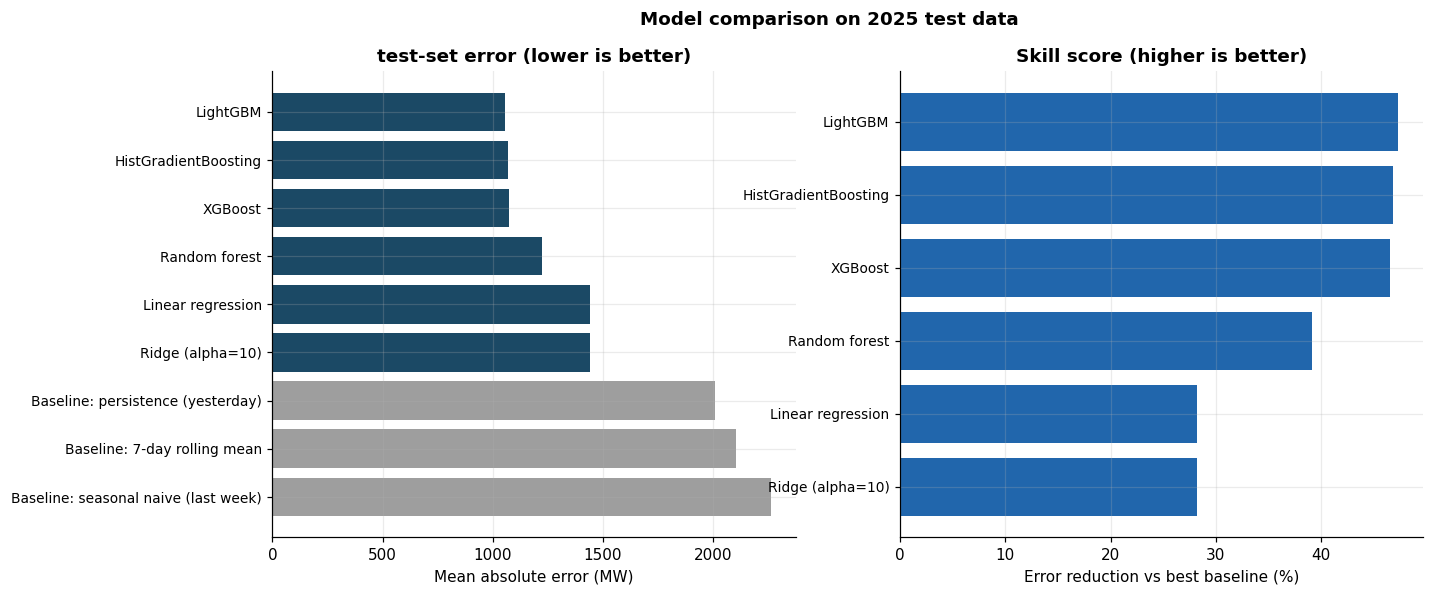

In [12]:
# Visual for comparison
fig,axes=plt.subplots(1,2, figsize=(13.5, 5.5))

comp_plot=comparison.sort_values("MAE", ascending=True)
colours=[C["muted"] if "Baseline" in m else C["primary"] for m in comp_plot.index]

axes[0].barh(range(len(comp_plot)), comp_plot["MAE"], color=colours)
axes[0].set_yticks(range(len(comp_plot)))
axes[0].set_yticklabels(comp_plot.index, fontsize=9)
axes[0].invert_yaxis()
axes[0].set_xlabel("Mean absolute error (MW)")
axes[0].set_title("test-set error (lower is better)")


skill=comp_plot[~comp_plot.index.str.contains("Baseline")]["skill_vs_baseline_%"]
axes[1].barh(range(len(skill)), skill.values,
             color=[C["good"] if v>0 else C["accent"] for v in skill.values])
axes[1].set_yticks(range(len(skill)))
axes[1].set_yticklabels(skill.index, fontsize=9)
axes[1].invert_yaxis()
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_xlabel("Error reduction vs best baseline (%)")
axes[1].set_title("Skill score (higher is better)")

fig.suptitle("Model comparison on 2025 test data", fontweight="bold")
fig.savefig(FIG_DIR/ "7_model_comparison.png")
plt.show()




### 7. Where does the error live?

The overall MAE tells us how far predictions were from actual demand on average during 2025 but it does not show when the model made larger or smaller errors.

This section breaks down the errors by half-hourly settlement period, season, working days, bank holidays and peak periods. It compares the selected model with the baseline to see where it performs better or worse.

MAE shows the average error in MW. MAPE expresses the error as a percentage of actual demand. A positive MAE reduction means the model made smaller errors than the baseline, a negative value means it made larger errors.

The calendar comparisons also show the number of observations in each group, as categories such as bank holidays have much less data.

These results help explain the model's performance. They are not used to change the selected model.

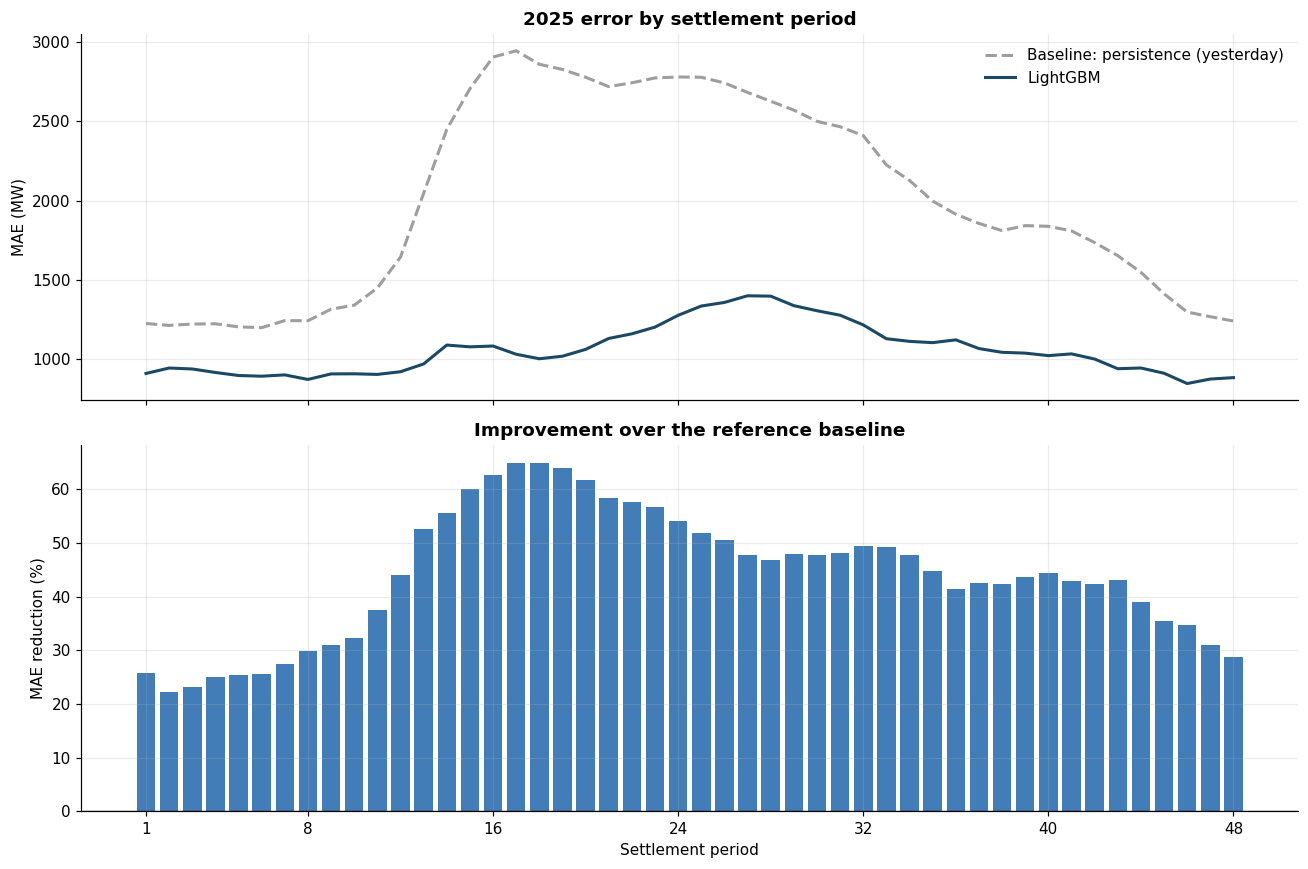

Worst 5 settlement periods by MAE:
                   model_mae  baseline_mae  mean_demand  mape_%  skill_%
settlement_period                                                       
27                    1400.1        2681.7      28402.0     5.0     47.8
28                    1397.7        2626.1      28246.4     5.0     46.8
26                    1358.0        2741.5      28468.5     4.8     50.5
29                    1337.9        2570.0      28299.6     4.8     47.9
25                    1335.4        2777.1      28572.8     4.7     51.9

Best 5 settlement periods by MAE:
                   model_mae  baseline_mae  mean_demand  mape_%  skill_%
settlement_period                                                       
46                     847.0        1297.4      27876.6     3.0     34.7
8                      872.8        1242.7      23811.0     3.7     29.8
47                     875.3        1268.3      26649.5     3.3     31.0
48                     884.2        1240.9      25820.

In [13]:
#Pairing the selected model's predictions with the 2025 test observations
test_eval = test_c.copy()
test_eval["pred"] = best_pred

# Positive residual: actual demand above prediction
# Negative residual: actual demand below prediction
test_eval["residual"] = (
    test_eval["tsd_mw"] - test_eval["pred"]
)

#Storing the same signed residual under the alternative column name "error"
test_eval["error"] = test_eval["residual"]

#Absoulte errors --> to measure magnitude without allowing opposite signs to cancel
test_eval["abs_error"] = test_eval["residual"].abs()
test_eval["pct_error"] = (
    test_eval["residual"] / test_eval["tsd_mw"] * 100
)
test_eval["abs_pct_error"] = test_eval["pct_error"].abs()

#Comparing against the baseline chosen using 2024 validation performance
baseline_pred = predictions[SELECTED_BASELINE_NAME]

test_eval["baseline_abs_error"] = np.abs(
    test_eval["tsd_mw"].to_numpy() - baseline_pred
)

#Average errors within each settlement period across the test year
#MAPE is the mean of individual absolute percentage errors
by_period = test_eval.groupby("settlement_period").agg(
    model_mae=("abs_error", "mean"),
    baseline_mae=("baseline_abs_error", "mean"),
    mean_demand=("tsd_mw", "mean"),
    mape_pct=("abs_pct_error", "mean")
)

#Expressing the model's MAE reduction relative to the baseline in each period.
#Positive values for the model, negative values for the baseline
by_period["skill_%"] = (
    1 - by_period["model_mae"] / by_period["baseline_mae"]
) * 100

by_period = by_period.rename(columns={"mape_pct": "mape_%"})

fig, axes = plt.subplots(
    2, 1, figsize=(12, 8), sharex=True
)

axes[0].plot(
    by_period.index,
    by_period["baseline_mae"],
    label=SELECTED_BASELINE_NAME,
    color=C["muted"],
    linewidth=2,
    linestyle="--"
)

axes[0].plot(
    by_period.index,
    by_period["model_mae"],
    label=SELECTED_MODEL_NAME,
    color=C["primary"],
    linewidth=2
)

axes[0].set_ylabel("MAE (MW)")
axes[0].set_title("2025 error by settlement period")
axes[0].legend(frameon=False)

axes[1].bar(
    by_period.index,
    by_period["skill_%"],
    color=C["good"],
    alpha=0.85
)

axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("MAE reduction (%)")
axes[1].set_xlabel("Settlement period")
axes[1].set_title("Improvement over the reference baseline")

#Keeping settlement-period numbers to avoid an inaccurate local clock-time mapping on daylight-saving transition days
axes[1].set_xticks([1, 8, 16, 24, 32, 40, 48])

fig.tight_layout()
fig.savefig(FIG_DIR / "8_error_by_period.png")
plt.show()

print("Worst 5 settlement periods by MAE:")
print(
    by_period.sort_values("model_mae", ascending=False)
    .head(5).round(1).to_string()
)

print("\nBest 5 settlement periods by MAE:")
print(
    by_period.sort_values("model_mae")
    .head(5).round(1).to_string()
)


In [14]:
#Comparing model and baseline errors across calendar and peak-period groups
#Observation counts show how much test data supports each comparison
print("ERROR BY CONTEXT")
print("-"*40)

for label, grouper in [("Season", "season"),
                       ("Working day", "is_working_day"),
                       ("Bank holiday", "is_bank_holiday"),
                       ("Peak period", "is_peak")]:
    g=test_eval.groupby(grouper).agg(
        n=("abs_error", "size"),
        model_mae=("abs_error", "mean"),
        baseline_mae=("baseline_abs_error", "mean"),
    )
    g["skill_%"]=(1-g["model_mae"] / g["baseline_mae"])*100
    print(f"\n{label}:")
    print(g.round(1).to_string())

ERROR BY CONTEXT
----------------------------------------

Season:
           n  model_mae  baseline_mae  skill_%
season                                        
Autumn  4368     1126.2        2039.2     44.8
Spring  4406      978.7        2009.9     51.3
Summer  4416      875.8        1836.3     52.3
Winter  4320     1252.6        2152.2     41.8

Working day:
                    n  model_mae  baseline_mae  skill_%
is_working_day                                         
0                5370     1038.9        2168.7     52.1
1               12140     1065.1        1937.7     45.0

Bank holiday:
                     n  model_mae  baseline_mae  skill_%
is_bank_holiday                                         
0                17126     1050.9        2003.7     47.6
1                  384     1332.9        2223.6     40.1

Peak period:
             n  model_mae  baseline_mae  skill_%
is_peak                                         
0        14590     1052.5        2020.0     47.9
1        

### 8. Incremental feature-group comparison

Examining how prediction error changes as calendar,
weather,generation/pumping features are added to historical demand. Each model uses the same LightGBM configuration selected through 2024 validation and is fitted on 2023–2024 data.
The 2025 results are used for interpretation only, not to change the selected feature set or model. Improvements depend on the order in
which groups are added and do not establish causal effects.

In [15]:
LAG_FEATURES=[c for c in FEATURES if c.startswith(("demand_lag", "demand_roll", "demand_wow"))]
CAL_FEATURES=[c for c in FEATURES if c in (
    "settlement_period", "hour", "hour_decimal", "is_peak", "year", "month",
        "day_of_week", "day_of_year", "is_weekend", "is_bank_holiday",
        "is_school_holiday", "is_working_day", "is_clock_change_day",
        "days_since_bank_holiday", "days_to_bank_holiday", "week_slot", "is_working_peak"
)]
WX_FEATURES=[c for c in FEATURES if c in (
    "temperature_c", "temperature_lag_1d", "temperature_roll_3d_avg", "wind_speed",
    "humidity_pct", "precipitation_mm", "cloud_cover_pct", "solar_radiation",
    "heating_degrees", "cooling_degrees"
)]
GEN_FEATURES=[c for c in FEATURES if c in (
    "embedded_wind_mw", "embedded_solar_mw", "pump_storage_mw"
)]

groups=[
    ("Lags only", LAG_FEATURES),
    ("Lags + calendar", LAG_FEATURES + CAL_FEATURES),
    ("Lags + calendar + weather", LAG_FEATURES + CAL_FEATURES + WX_FEATURES),
    ("All features", FEATURES),
]

ablation = []

for label, cols in groups:
    #Preserving feature order and removing any duplicates
    cols = list(dict.fromkeys(cols))

    if cols == FEATURES:
        # Reusing the already evaluated selected model
        pred = best_pred
    else:
        model = clone(selected_template)
        model.fit(X_train[cols], y_train)
        pred = model.predict(X_test[cols])

    row = evaluate(y_test, pred, label)
    row["n_features"] = len(cols)
    ablation.append(row)

abl = pd.DataFrame(ablation).set_index("model")

abl["skill_vs_baseline_%"] = (
    1 - abl["MAE"] / BASELINE_MAE
) * 100

#Positive means the added group reduced MAE
# Negative means the added group increased MAE
abl["gain_over_previous"] = -abl["MAE"].diff()

print(
    f"INCREMENTAL FEATURE-GROUP COMPARISON - "
    f"{SELECTED_MODEL_NAME}"
)
print(f"Configuration: {SELECTED_CONFIGURATION}")
print("Evaluation period: 2025\n")

print(
    abl[[
        "n_features",
        "MAE",
        "RMSE",
        "MAPE",
        "skill_vs_baseline_%",
        "gain_over_previous"
    ]].round(2).to_string()
)

INCREMENTAL FEATURE-GROUP COMPARISON - LightGBM
Configuration: smaller_trees
Evaluation period: 2025

                           n_features      MAE     RMSE  MAPE  skill_vs_baseline_%  gain_over_previous
model                                                                                                 
Lags only                          11  1653.59  2247.00  5.87                17.67                 NaN
Lags + calendar                    28  1451.74  1898.21  5.18                27.72              201.85
Lags + calendar + weather          38  1222.37  1584.21  4.37                39.14              229.36
All features                       41  1057.09  1361.43  3.72                47.37              165.28


### 9. Feature importance

Feature importance shows how much the model's average prediction error(MAE) changes when the values of one input are randomly shuffled. A larger increase means the model depends more on that input.

The analysis uses a repeatable sample of up to 6,000 observations from 2025, with 5 shuffles per input. Error bars show how much the importance scores vary across the 5 shuffles.

Correlated features can substitute for one another --> a low score does not necessarily mean a feature is uninformative. The results do not prove cause and effect
and are not used to change the selected model or its inputs.


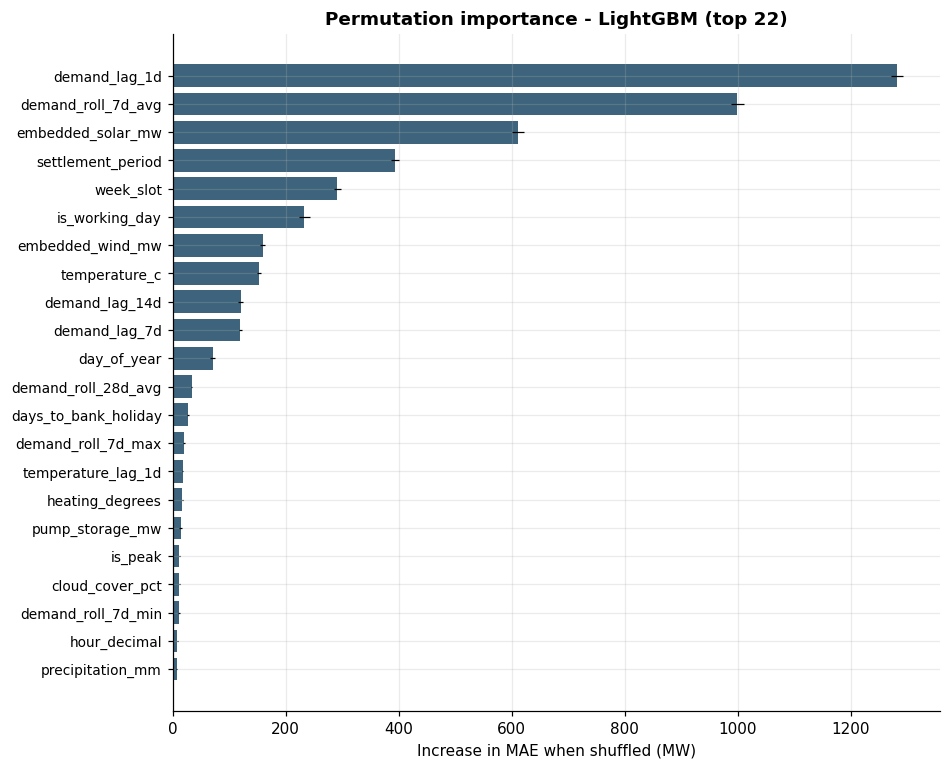

Full ranking:
                feature  importance   std
          demand_lag_1d     1282.59 10.88
     demand_roll_7d_avg      999.56 10.89
      embedded_solar_mw      610.91 10.43
      settlement_period      393.64  7.00
              week_slot      291.57  6.50
         is_working_day      232.60  9.79
       embedded_wind_mw      159.08  4.05
          temperature_c      152.86  3.96
         demand_lag_14d      120.57  4.34
          demand_lag_7d      120.00  3.37
            day_of_year       70.94  4.61
    demand_roll_28d_avg       33.45  1.12
   days_to_bank_holiday       27.76  1.58
     demand_roll_7d_max       19.68  1.45
     temperature_lag_1d       18.09  0.97
        heating_degrees       17.35  1.03
        pump_storage_mw       13.88  2.80
                is_peak       11.64  1.07
        cloud_cover_pct       11.44  0.93
     demand_roll_7d_min       11.13  1.36
           hour_decimal        8.38  1.28
       precipitation_mm        6.90  0.37
days_since_bank_holi

In [16]:
# Permutation importance on a sample (it does predict n_repeats times per feature
# --> full test would be slow)

sample_idx=np.random.RandomState(42).choice(len(X_test), size=min(6000, len(X_test)), replace=False)

model_for_imp = selected_model  
perm=permutation_importance(
    model_for_imp, X_test.iloc[sample_idx], y_test.iloc[sample_idx],
    n_repeats=5, random_state=42, n_jobs=-1, scoring="neg_mean_absolute_error"
)

imp=(pd.DataFrame({"feature": FEATURES,
                   "importance": perm.importances_mean,
                   "std": perm.importances_std})
                   .sort_values("importance", ascending=False)
                   .reset_index(drop=True))

fig, ax = plt.subplots(figsize=(9, 8))
top = imp.head(22).iloc[::-1]
ax.barh(range(len(top)), top["importance"], xerr=top["std"],
        color=C["primary"], alpha=0.85, error_kw={"linewidth": 0.8})
ax.set_yticks(range(len(top)))
ax.set_yticklabels(top["feature"], fontsize=9)
ax.set_xlabel("Increase in MAE when shuffled (MW)")
ax.set_title(f"Permutation importance - {SELECTED_MODEL_NAME} (top 22)")
fig.savefig(FIG_DIR / "9_feature_importance.png")
plt.show()

print("Full ranking:")
print(imp.round(2).to_string(index=False))




#### Interpretation

The model relies most on yesterday's demand and the 7-day average.
Embedded solar generation, settlement period, position within the week and working-day status also help its predictions.

### 10. Diagnostics on the best model

- Checking if predictions track reality over a sample week
- Checking if there is signal the model has not captured

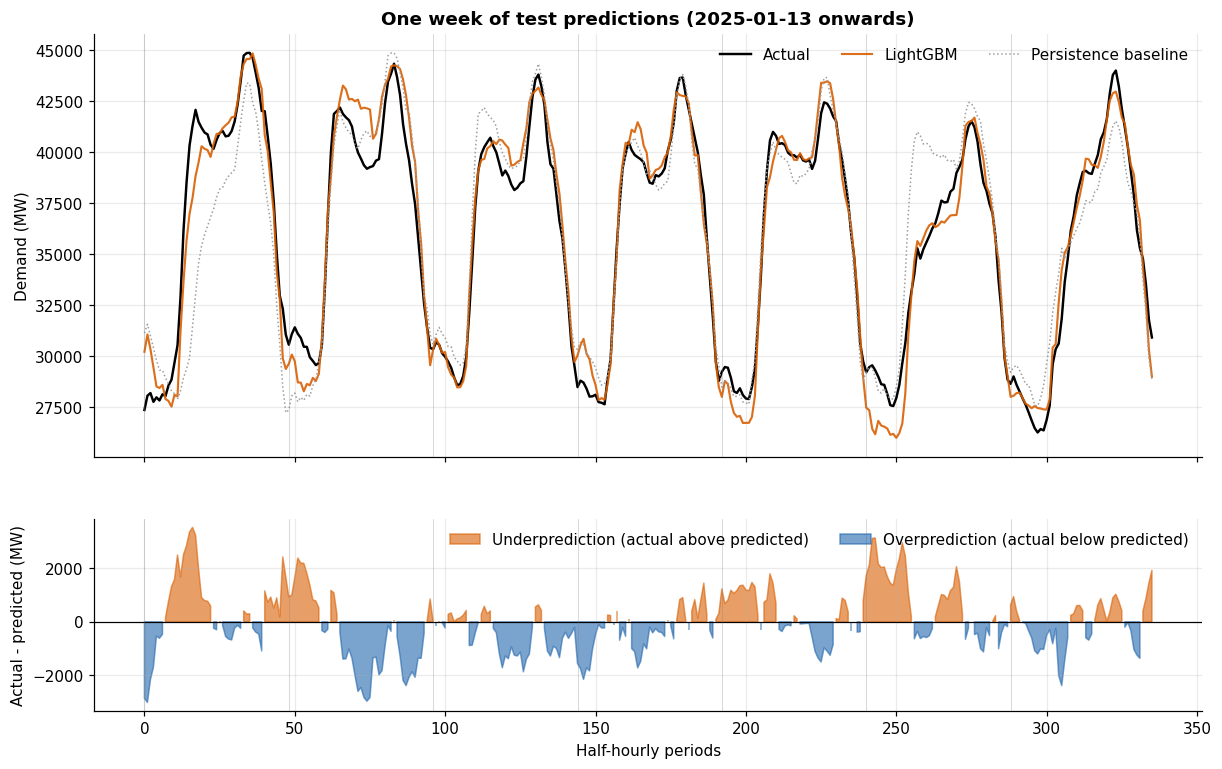

In [17]:
#Picking a representative week from the test set (in winter , when demand is hardest)

week_start=pd.Timestamp("2025-01-13")
mask=(test_eval["date"]>=week_start) & (test_eval["date"] < week_start + pd.Timedelta(days=7))
wk=test_eval[mask].sort_values(["settlement_date", "settlement_period"]).reset_index(drop=True)

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True,
                         gridspec_kw={"height_ratios": [2.2, 1]})

axes[0].plot(wk.index, wk["tsd_mw"], label="Actual", color="black", linewidth=1.6)
axes[0].plot(wk.index, wk["pred"], label=BEST_MODEL_NAME, color=C["accent"],
             linewidth=1.4, alpha=0.9)
axes[0].plot(wk.index, wk["demand_lag_1d"], label="Persistence baseline",
             color=C["muted"], linewidth=1, linestyle=":")
axes[0].set_ylabel("Demand (MW)")
axes[0].set_title(f"One week of test predictions ({wk['settlement_date'].iloc[0]} onwards)")
axes[0].legend(frameon=False, ncol=3)

axes[1].fill_between(
    wk.index, wk["residual"], 0,
    where=wk["residual"] >= 0,
    color=C["accent"],
    alpha=0.6,
    label="Underprediction (actual above predicted)"
)

axes[1].fill_between(
    wk.index, wk["residual"], 0,
    where=wk["residual"] < 0,
    color=C["good"],
    alpha=0.6,
    label="Overprediction (actual below predicted)"
)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("Actual - predicted (MW)")
axes[1].set_xlabel("Half-hourly periods")
axes[1].legend(frameon=False, ncol=2)


#Day boundaries
for d in range(0, len(wk),48):
    for a in axes: a.axvline(d, color="grey", linewidth=0.4, alpha=0.5)

fig.savefig(FIG_DIR / "10_sample_week.png")
plt.show()

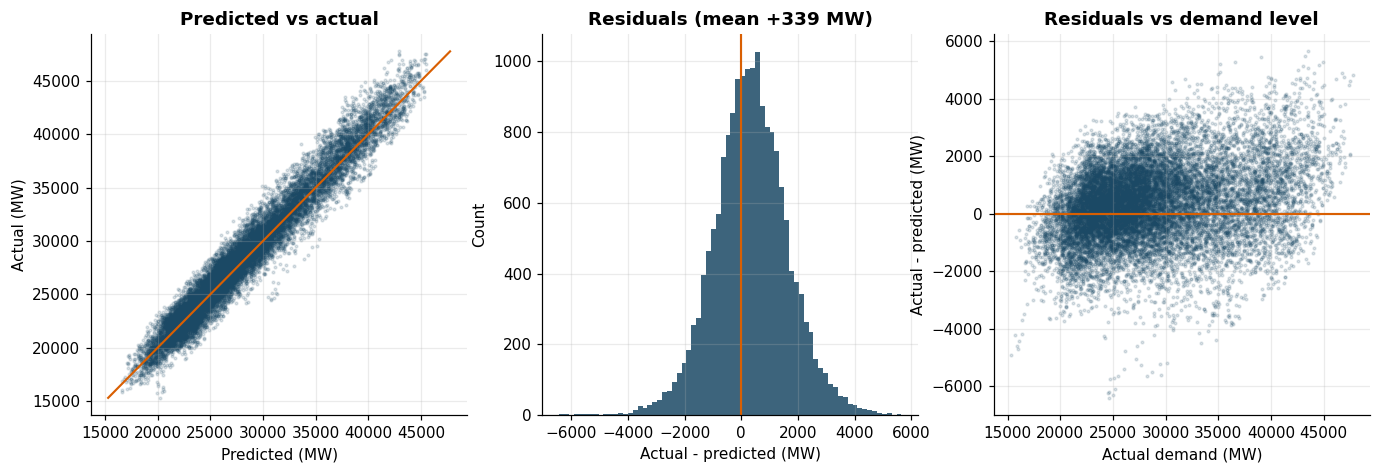

Mean residual: +339.2 MW
Residual standard deviation: 1,318.5 MW
Predictions were 339.2 MW below actual demand on average.

The mean residual describes average prediction bias, positive and negative errors can cancel.
The residual plots help identify systematic patterns and changes in error spread across demand levels.


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].scatter(test_eval["pred"], test_eval["tsd_mw"], s=3, alpha=0.15, color=C["primary"])
lims = [test_eval["tsd_mw"].min(), test_eval["tsd_mw"].max()]
axes[0].plot(lims, lims, color=C["accent"], linewidth=1.4)
axes[0].set_xlabel("Predicted (MW)"); axes[0].set_ylabel("Actual (MW)")
axes[0].set_title("Predicted vs actual")

axes[1].hist(test_eval["residual"], bins=70, color=C["primary"], alpha=0.85)
axes[1].axvline(0, color=C["accent"], linewidth=1.4)
axes[1].set_xlabel("Actual - predicted (MW)"); axes[1].set_ylabel("Count")
axes[1].set_title(f"Residuals (mean {test_eval['residual'].mean():+,.0f} MW)")

axes[2].scatter(test_eval["tsd_mw"], test_eval["residual"], s=3, alpha=0.15, color=C["primary"])
axes[2].axhline(0, color=C["accent"], linewidth=1.4)
axes[2].set_xlabel("Actual demand (MW)"); axes[2].set_ylabel("Actual - predicted (MW)")
axes[2].set_title("Residuals vs demand level")

fig.savefig(FIG_DIR / "11_residual_diagnostics.png")
plt.show()




mean_residual = test_eval["residual"].mean()

print(f"Mean residual: {mean_residual:+,.1f} MW")
print(
    f"Residual standard deviation: "
    f"{test_eval['residual'].std():,.1f} MW"
)

if mean_residual > 0:
    print(
        f"Predictions were {mean_residual:,.1f} MW "
        "below actual demand on average."
    )
elif mean_residual < 0:
    print(
        f"Predictions were {abs(mean_residual):,.1f} MW "
        "above actual demand on average."
    )
else:
    print("The average signed residual was zero.")

print(
    "\nThe mean residual describes average prediction bias, "
    "positive and negative errors can cancel."
)
print(
    "The residual plots help identify systematic patterns "
    "and changes in error spread across demand levels."
)

### 11. Saving results

In [19]:
to_save=[]

for name, pred in predictions.items():
    to_save.append(pd.DataFrame({
        "settlement_date":      test_c["settlement_date"].values,
        "settlement_period":    test_c["settlement_period"].values,
        "model_name":           name,
        "predicted_demand_mw":  pred,
        "data_split":          "test",
    }))
preds_df=pd.concat(to_save, ignore_index=True)

conn.execute("""
    CREATE TABLE IF NOT EXISTS model_predictions (
        settlement_date     TEXT    NOT NULL,
        settlement_period   INTEGER NOT NULL,
        model_name          TEXT    NOT NULL,
        predicted_demand_mw REAL,
        data_split          TEXT CHECK (data_split IN ('train', 'validation', 'test')),
        created_at          TEXT DEFAULT (datetime('now')),
        PRIMARY KEY (settlement_date, settlement_period, model_name)
    );
""")

conn.execute("DELETE FROM model_predictions WHERE data_split = 'test' OR data_split IS NULL;")
preds_df.to_sql("model_predictions", conn, if_exists="append", index=False)
conn.commit()

n=conn.execute("SELECT COUNT(*) FROM model_predictions;").fetchone()[0]
print(f"model_predictions now holds {n:,} rows across {preds_df['model_name'].nunique()} models")

comparison.round(3).to_csv(PROJECT_ROOT / "data" / "processed" / "model_comparison.csv")
print("saved: data/processed/model_comparison.csv")

import json
import joblib
from importlib.metadata import version

processed_dir = PROJECT_ROOT / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

model_dir = PROJECT_ROOT / "models"
model_dir.mkdir(parents=True, exist_ok=True)

#Saving the validation evidence behind model selection
cv_results.to_csv(
    processed_dir / "model_validation_folds.csv",
    index=False
)

tuning_results.to_csv(
    processed_dir / "model_tuning_folds.csv",
    index=False
)

tuning_summary.to_csv(
    processed_dir / "model_tuning_summary.csv"
)

#Saving the explanatory analyses
abl.to_csv(
    processed_dir / "feature_group_comparison.csv"
)

imp.to_csv(
    processed_dir / "permutation_importance.csv",
    index=False
)

# Saving the selected model's 2025 predictions and residuals
selected_eval = test_eval[[
    "settlement_date",
    "settlement_period",
    "tsd_mw",
    "pred",
    "residual",
    "abs_error"
]].copy()

selected_eval = selected_eval.rename(columns={
    "tsd_mw": "actual_demand_mw",
    "pred": "predicted_demand_mw",
    "residual": "residual_mw",
    "abs_error": "abs_error_mw"
})

selected_eval["model_name"] = SELECTED_MODEL_NAME

selected_eval.to_csv(
    processed_dir / "selected_model_test_predictions.csv",
    index=False
)

#Saving the fitted model together with its required feature order
joblib.dump(
    {
        "model": selected_model,
        "features": list(FEATURES),
        "target": TARGET
    },
    model_dir / "selected_demand_model.joblib"
)

#Recording how the model was selected and evaluated
metadata = {
    "selected_model": SELECTED_MODEL_NAME,
    "configuration": SELECTED_CONFIGURATION,
    "parameters": selected_model.get_params(),
    "reference_baseline": SELECTED_BASELINE_NAME,
    "selection_metric": "Mean MAE across four 2024 validation quarters",
    "training_start": str(train_c["settlement_date"].min()),
    "training_end": str(train_c["settlement_date"].max()),
    "test_start": str(test_c["settlement_date"].min()),
    "test_end": str(test_c["settlement_date"].max()),
    "features": list(FEATURES),
    "target": TARGET,
    "residual_definition": "actual minus predicted",
    "experiment": (
        "Historical benchmark using observed contemporaneous "
        "weather, embedded generation and pumping."
    ),
    "evaluation_note": (
        "2025 was previously inspected during project development. "
        "The revised selection procedure uses 2024 validation."
    ),
    "package_versions": {
        package: version(package)
        for package in [
            "scikit-learn", "lightgbm", "xgboost",
            "pandas", "numpy", "joblib"
        ]
    }
}

with open(
    model_dir / "selected_demand_model_metadata.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(metadata, file, indent=2, default=str)

print("Saved validation results, diagnostics, model and metadata.")

conn.close()
print("Connection closed")



model_predictions now holds 157,590 rows across 9 models
saved: data/processed/model_comparison.csv
Saved validation results, diagnostics, model and metadata.
Connection closed
